In [66]:
import numpy as np
import pandas as pd
import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
import optax
import unittest
from functools import partial 
from tensorboard import notebook
from sklearn.preprocessing import MinMaxScaler
from scipy.special import logsumexp
import jax.profiler
import time

import matplotlib.pyplot as plt

# Main functions

In [67]:
def loss_fn(z, inds, Sigma_tilde_vec, d):
    """
    z [jnp.array]: vector supporting precision matrix estimate K(z)
    inds [np.array]: list of the lower triangular nonzero element indices in Sigma_tilde
    Sigma_tilde_vec [np.array]: vector of Sigma_tilde indexed at inds
    d [int]: static argument, number of attributes 
    """

    # Reconstruct K_z
    K_z = get_K(z, inds, d)

    # Get loss terms
    log_det_term = logdet_psd(K_z)
    trace_term = 2 * jnp.dot(z, Sigma_tilde_vec)

    # Total loss
    total_loss = -log_det_term + trace_term

    # # uncomment to print eigenvalues and PSD status during learning
    
    # eigenvalues = jnp.linalg.eigvalsh(K_z)
    # is_psd = jnp.all(eigenvalues >= 0)

    # def raise_nonpsd_flag(x):
    #     jax.debug.print("K_z not PSD")
    #     return x  # Return the same type as total_loss

    # total_loss = jax.lax.cond(
    #     is_psd,                     # Condition
    #     raise_nonpsd_flag,          # True branch function
    #     lambda x: x,                # False branch function
    #     total_loss                  # Argument passed to both branches
    # )
    
    return total_loss


def get_K(z, inds, d):
    """
    z [jnp.array]: vector supporting precision matrix estimate K(z)
    inds [np.array]: list of the lower triangular nonzero element indices in Sigma_tilde
    d: dimension of Sigma_tilde
    """

    rows = inds[:,0]
    cols = inds[:,1]
    
    K = jnp.zeros((d, d))
    
    # Write lower triangle
    K = K.at[rows, cols].add(z)

    # Write upper triangle (diagonal elements are counted twice, see initialize_z)
    K = K.at[cols, rows].add(z)
    #jax.debug.print("K: {}", K)
    
    return K
    

def initialize_z(Sigma_tilde, inds):
    """
        Sigma_tilde [np.array]: matrix of observed (privatized) covariance entries
        inds [np.array]: vector of indices of nonzero covariance entries
    """

    d = Sigma_tilde.shape[0]

    z_init = []
    
    for (i,j) in inds:
        if i == j:
            z_init.append( max(0.01, 1./Sigma_tilde[i,j]) / 2 ) # diagonal is halved to match K construction in get_K
        else:
            z_init.append(0)
        
    return jnp.array(z_init)


def optimize_lbfgs(Sigma_tilde_vec, z, inds, d, max_iters=100, verbose=False):
    """
    Sigma_tilde_vec [np.array]: matrix of observed (privatized) covariance entries
    z [jnp.array]: vector supporting K(z)
    inds [np.array]: vector of indices of nonzero covariance entries
    d [int]: number of attributes
    """
   
    # linesearch
    linesearch = optax.scale_by_zoom_linesearch(max_linesearch_steps=15)
    
    # set up optimizer
    opt = optax.chain(
        optax.lbfgs(),
        linesearch,
    )
    
    # init state
    state = opt.init(z)

    # loss function wrapper
    loss_fn_wrapper = partial(loss_fn, inds=inds, Sigma_tilde_vec=Sigma_tilde_vec, d=d)

    # Create the value and gradient function using the partially applied function (compiled once)
    v_and_g = jax.value_and_grad(loss_fn_wrapper)

    # jax.jitted optimization step
    @jax.jit
    def optimization_step(z, state):
        v, g = v_and_g(z)
        updates, state = opt.update(g, state, z, value=v, grad=g, value_fn=loss_fn_wrapper)
        z = optax.apply_updates(z, updates)
        grad_sum = jnp.sum(jnp.abs(g))
        return z, state, v, grad_sum

    # optimizat9ion loop
    g_vals = []
    obj_vals = []

    for i in range(max_iters):
        start_time = time.time()
        z, state, v, grad_sum = optimization_step(z, state)
        end_time = time.time()
        duration = end_time - start_time
        
        if verbose:
            print(f"Iteration {i}: Duration = {duration:.4f} seconds")
            print(f"iter: {i}, value: {v:.7e}")
            print(f"grad sum: {grad_sum:.7e}")

        if i % 500 == 0:
            jax.debug.print("z: {}", z)
            curr_K = get_K(z, inds, d)
            print("\n")
            print("eigenvalues of K:", jnp.linalg.eig(curr_K))
            print("\n")
            print(f"K {curr_K}, CHECK PSD {is_positive_semidefinite(curr_K)}")
            print("\n")
            print(f"Sigma_hat {np.linalg.inv(curr_K)}")

        obj_vals.append(v.item())
        g_vals.append(grad_sum.item())

    return z, g_vals, obj_vals
    

# Helpers

In [110]:
def preprocess(data):
    """
    attribute rescaling between -1 and 1 needed for sensitivity analysis   
    """
    scaler = MinMaxScaler(feature_range=(-1, 1))
    scaled_data = scaler.fit_transform(data)
    scaled_df = pd.DataFrame(scaled_data, columns=data.columns)

    return scaled_df 

def get_observed_Sigma_entries(Sigma):
    """
    extract the indices of the observed entries in Sigma  
    """

    d = Sigma.shape[0]

    diag_inds = [(i,i) for i in range(d)]   # assumed it's always observed
    tril_inds = get_strict_lower_triangle_nonzero(Sigma)
    triu_inds = [(j,i) for (i, j) in tril_inds]

    all_observed_inds = diag_inds + tril_inds + triu_inds

    return np.array(all_observed_inds)

def compute_d(inds):
    mask = (inds[:, 0] == inds[:, 1])
    d = np.sum(mask)
    return d

def reconstruct_sigma_tilde(inds, sigma_tilde_vec, d):
    Sigma_tilde = np.zeros((d, d))
    
    rows = inds[:, 0]
    cols = inds[:, 1]
    
    # Populate the matrix at the positions indicated by inds
    Sigma_tilde[rows, cols] = sigma_tilde_vec
    Sigma_tilde[cols, rows] = sigma_tilde_vec  # Fill in the symmetric counterparts
    
    return Sigma_tilde

def is_positive_definite(M):
    return jnp.all(jnp.linalg.eigvalsh(M) > 0)

def is_positive_semidefinite(M):
    return jnp.all(jnp.linalg.eigvalsh(M) >= 0)

def get_strict_lower_triangle_nonzero(M):
    # lower triangle indices excluding the diagonal
    lower_triangle_indices = np.tril_indices(M.shape[0], k=-1)
    
    # nonzero elements in the lower triangle
    nonzero_mask = M[lower_triangle_indices] != 0
    filtered_indices = (lower_triangle_indices[0][nonzero_mask], lower_triangle_indices[1][nonzero_mask])
    
    # zip indices together into tuples
    indices_tuples = list(zip(filtered_indices[0].tolist(), filtered_indices[1].tolist()))
    
    return indices_tuples

@jax.jit
def logdet_psd(A):
    """
    computes log determinand and determines if A is PSD
    """
    # compute the Cholesky decomposition
    L = jnp.linalg.cholesky(A)

    # Check if any entry of the Cholesky factor is NaN
    is_nan = jnp.any(jnp.isnan(L))

    def nan_case(_):
        return -jnp.inf

    def valid_case(L):
        diag_L = jnp.diag(L)
        log_det = 2 * jnp.sum(jnp.log(diag_L))
        return log_det

    # Use jax.cond to choose between the cases
    return jax.lax.cond(is_nan, nan_case, valid_case, L)


def generate_chain_structure(Sigma_true):
    """
    Generate a chain structure where only the diagonal and adjacent subdiagonal entries are non-zero.
    
    Parameters:
    - Sigma_true: np.array, true covariance matrix.

    Returns:
    - Sigma_tilde: np.array, covariance matrix with chain structure.
    """
    d = Sigma_true.shape[0]
    Sigma_tilde = np.zeros_like(Sigma_true)
    np.fill_diagonal(Sigma_tilde, np.diagonal(Sigma_true))

    # Set adjacent subdiagonal entries
    for i in range(1, d):
        Sigma_tilde[i, i-1] = Sigma_true[i, i-1]
        Sigma_tilde[i-1, i] = Sigma_true[i-1, i]

    return Sigma_tilde

def generate_custom_structure(Sigma_true, structure_dict):
    """
    Generate a custom structure based on the provided structure dictionary.

    Parameters:
    - Sigma_true: np.array, true covariance matrix.
    - structure_dict: dict, specifies which elements to keep non-zero.

    Returns:
    - Sigma_tilde: np.array, covariance matrix with custom structure.
    """
    Sigma_tilde = np.zeros_like(Sigma_true)
    np.fill_diagonal(Sigma_tilde, np.diagonal(Sigma_true))
    
    if not structure_dict:
        return Sigma_tilde  # return just the diagonal

    # Set custom entries
    for (i, j) in structure_dict.get('off_diag_positions', []):
        Sigma_tilde[i, j] = Sigma_true[i, j]
        Sigma_tilde[j, i] = Sigma_true[j, i]

    return Sigma_tilde

def compute_mses(inds, Sigma_true, Sigma_opt):

    rows, cols = inds[:, 0], inds[:, 1]

    # mse at positions in inds (observed positions)
    Sigma_true_inds = Sigma_true[rows, cols]
    Sigma_opt_inds = Sigma_opt[rows, cols]
    mse_inds = np.mean((Sigma_true_inds - Sigma_opt_inds) ** 2)

    # mse at positions not in inds
    mask = np.ones(Sigma_true.shape, dtype=bool)
    mask[rows, cols] = False  # Set observed positions to False

    Sigma_true_not_inds = Sigma_true[mask]
    Sigma_opt_not_inds = Sigma_opt[mask]
    mse_not_inds = np.mean((Sigma_true_not_inds - Sigma_opt_not_inds) ** 2)

    # overall mse across all positions
    mse_all = np.mean((Sigma_true - Sigma_opt) ** 2)

    # Return a dictionary with all the computed MSEs
    return {
        'mse_inds': mse_inds,  
        'mse_not_inds': mse_not_inds,  
        'mse_all': mse_all  
    }

def plot_mses_over_iterations(results_dict):
    """
    Plot the different MSEs over iterations from the results of run_iterative_mode.
    
    Parameters:
    results_dict (dict): A dictionary containing MSEs and other results from run_iterative_mode.
    """
    mses_vec = results_dict['mses']

    mse_inds_list = []
    mse_not_inds_list = []
    mse_all_list = []

    # extract mse values for each iteration
    for mses in mses_vec:
        mse_inds_list.append(mses['mse_inds'])
        mse_not_inds_list.append(mses['mse_not_inds'])
        mse_all_list.append(mses['mse_all'])

    x_ticks = [str(i) for i in range(len(mse_inds_list))]

    plt.figure(figsize=(10, 6))
    plt.plot(x_ticks, mse_inds_list, label='MSE at observed positions (inds)', marker='o')
    plt.plot(x_ticks, mse_not_inds_list, label='MSE at unobserved positions (not inds)', marker='o')
    plt.plot(x_ticks, mse_all_list, label='Overall MSE (all positions)', marker='o')
    plt.title('MSEs over Iterations')
    plt.xlabel('Iteration')
    plt.ylabel('Mean Squared Error')
    plt.legend()

    plt.show()

# Tests

In [33]:
class TestAuxiliaryFunctions(unittest.TestCase):
    def test_get_K(self):
        d = 3
        z = np.array([0.5, 1., 1.5, 4., 5.])
        # Updated indices to be within bounds for a 3x3 matrix
        inds = np.array([(0, 0), (1, 1), (2, 2), (1, 0), (2, 0)])
        
        K_result = get_K(z, inds, d)
        
        # Updated expected result matrix based on the new indices
        K_true = np.array([[1., 4., 5.],
                           [4., 2., 0.],
                           [5., 0., 3.]])

        print(K_true)
        print(K_result)
        
        assert np.allclose(K_result, K_true, atol=1e-10), "test_get_K failed"

    def test_initialize_z(self):
        Sigma_tilde = np.array([[1000., 0., 4.],
                               [0., 2., 0.],
                               [4., 0., 3.]])
        inds = np.array([(0, 0), (1, 1), (2, 2), (2, 0)])
        d = Sigma_tilde.shape[0]
        
        z_true = np.array([0.01 / 2., 
                           1/2 / 2., 
                           1/3 / 2., 
                           0.])  
        
        z_init = initialize_z(Sigma_tilde, inds)

        for i in range(d):
            self.assertTrue(np.allclose(z_true, z_init, atol=1e-10)), "test_initialize_z failed"

    def test_trace_terms(self):
        np.random.seed(1)
        d = 4
        n = 100
        x = np.random.randn(n,d)
        
        Sigma = x.T.dot(x)
        
        # observed indices
        inds = np.array([[0, 0], [1, 1], [2,2], [3, 3], [3, 0]])
        z = np.array([10/2., 20/2., 30/2., 40/2., 50]) # diagonal entries are halved
        
        rows = inds[:,0]
        cols = inds[:,1]
        
        Sigma_tilde = np.zeros((d,d))
        Sigma_tilde[rows, cols] = Sigma[rows, cols]
        Sigma_tilde[cols, rows] = Sigma[cols, rows]
        
        Sigma_tilde_vec = Sigma_tilde[rows, cols]
        
        print(f"Sigma:\n{Sigma}\n")
        print(f"Sigma_tilde:\n{Sigma_tilde}\n")
        print(f"Sigma_tilde_vec:\n{Sigma_tilde_vec}\n")
        
        K = get_K(z, inds, d)
        
        print(f"z: {z}")
        print(f"K: {K}")
        
        trace_term_1 = np.trace(K.dot(Sigma_tilde))
        print(f"trace_term_1, {trace_term_1}")
        
        trace_term_2 = 2*np.dot(Sigma_tilde_vec, z)
        print(f"trace_term_2, {trace_term_2}")

        assert np.allclose(trace_term_1, trace_term_2, atol=1e-10), "test_trace_terms failed"
            
unittest.main(argv=[''], verbosity=2, exit=False)

test_get_K (__main__.TestAuxiliaryFunctions) ... ok
test_initialize_z (__main__.TestAuxiliaryFunctions) ... ok
test_trace_terms (__main__.TestAuxiliaryFunctions) ... ok

----------------------------------------------------------------------
Ran 3 tests in 0.022s

OK


[[1. 4. 5.]
 [4. 2. 0.]
 [5. 0. 3.]]
[[1. 4. 5.]
 [4. 2. 0.]
 [5. 0. 3.]]
Sigma:
[[102.50631974 -27.85384821   5.40372564  -7.11780264]
 [-27.85384821  92.12516717   3.94075161  -4.00545589]
 [  5.40372564   3.94075161  88.87655612   4.90562789]
 [ -7.11780264  -4.00545589   4.90562789  98.74319209]]

Sigma_tilde:
[[102.50631974   0.           0.          -7.11780264]
 [  0.          92.12516717   0.           0.        ]
 [  0.           0.          88.87655612   0.        ]
 [ -7.11780264   0.           0.          98.74319209]]

Sigma_tilde_vec:
[102.50631974  92.12516717  88.87655612  98.74319209  -7.11780264]

z: [ 5. 10. 15. 20. 50.]
K: [[10.  0.  0. 50.]
 [ 0. 20.  0.  0.]
 [ 0.  0. 30.  0.]
 [50.  0.  0. 40.]]
trace_term_1, 8771.810644126275
trace_term_2, 8771.810644126275


# DP

In [105]:
def cov_jk_sensitivity(n):
    Delta_cov_jk = 4 * (n - 1) / n**2
    return Delta_cov_jk

def exponential_mechanism(off_diag_errors, rho, alpha, Delta_cov_jk, rounds):
    # compute the log of the unnormalized probabilities
    log_unnorm_probabilities = ((2 * np.sqrt(rho * (1-alpha) / rounds)) / (2 * Delta_cov_jk)) * np.array(off_diag_errors)
    
    # compute log-sum-exp to normalize probabilities
    log_prob_sum = logsumexp(log_unnorm_probabilities)
    
    # compute normalizd probabilities using log-probabilities
    off_diag_probabilities = np.exp(log_unnorm_probabilities - log_prob_sum)
    print("off_diag_probabilities", off_diag_probabilities)

    # select
    worst_off_diag_index = np.random.choice(len(off_diag_errors), p=off_diag_probabilities)
    
    return worst_off_diag_index

# Drivers

In [106]:
def run_driver(data_path, structure='custom', structure_dict=None, max_iters=50, 
               iterative=False, max_off_diag_percentage=0.5, apply_dp=False, rho=None, alpha=None):
    """
    General driver function for processing different datasets with flexible off-diagonal configurations.

    Parameters:
    - data_path: str, path to the dataset file.
    - structure: str, predefined structure ('chain', 'custom', etc.) or 'custom' for user-defined.
    - structure_dict: dict, specifies the non-zero elements for custom structures.
    - max_iters: int, maximum number of iterations for optimization.
    - iterative: bool, whether to run in iterative mode.
    - max_off_diag_percentage: float, maximum percentage of off-diagonal elements to observe in iterative mode.

    Returns:
    - results_dict: dict, contains mse, gradient values, objective values, and other metadata.
    """

    # Load dataset
    data = pd.read_csv(data_path)
    print("data", data)
    data = preprocess(data)
    n, d = data.to_numpy().shape
    Sigma_true = data.cov().to_numpy()
    T = np.max(np.linalg.norm(data, axis=1, ord=2))

    # Define different structures
    if structure == 'chain':
        Sigma_tilde = generate_chain_structure(Sigma_true)
    elif structure == 'custom':
        Sigma_tilde = generate_custom_structure(Sigma_true, structure_dict)
    else:
        raise ValueError("Invalid structure. Choose 'chain', 'custom', or provide a valid structure dictionary.")

    # Non-iterative and iterative modes
    if iterative:
        results_dict = run_iterative_mode(n, Sigma_true, Sigma_tilde, max_iters, max_off_diag_percentage, apply_dp, rho, alpha)
    else:
        results_dict = run_non_iterative_mode(n, Sigma_true, Sigma_tilde, max_iters, apply_dp, rho, alpha)
    
    return results_dict

def run_iterative_mode(n, Sigma_true, Sigma_tilde, max_iters, max_off_diag_percentage, apply_dp, rho, alpha):
    """
    Run the driver in iterative mode.
    """
    d = Sigma_true.shape[0]

    rows_offdiag, cols_offdiag = np.tril_indices(d, k=-1)
    off_diag_indices = np.array(list(zip(rows_offdiag, cols_offdiag)))
    total_off_diag = len(off_diag_indices)
    max_off_diag_observed = int(max_off_diag_percentage * total_off_diag)
    rounds = max_off_diag_observed
    # max_off_diag_observed = 2
    # rounds = 2
    
    off_diag_observed = 0
    mses_vec = []

    seen = {}

    if apply_dp:
        Delta_cov_jk = cov_jk_sensitivity(n)
        s_m = 1 / np.sqrt(rho * alpha)
        s_v = 1 / np.sqrt(rho * alpha)
        s_c = np.sqrt(rounds / rho*(1-alpha))
        print(f"s_v {s_v}, s_v {s_c}")
        # # uncomment for 0 noise in apply_dp mode for debugging
        # s_m = 0
        # s_v = 0
        # s_c = 0
        Sigma_tilde = Sigma_tilde + np.eye(d) * np.random.normal(0, 1, size = (d,1)) * s_v * d * Delta_cov_jk 
    
    while off_diag_observed <= rounds:

        inds = get_observed_Sigma_entries(Sigma_tilde)
        rows, cols = inds[:, 0], inds[:, 1]
        Sigma_tilde_vec = Sigma_tilde[rows, cols]

        # initialize z and K
        z_init = initialize_z(Sigma_tilde, inds)
        K_z_init = get_K(z_init, inds, d)

        # optimization
        z_opt, g_vals, obj_vals = optimize_lbfgs(Sigma_tilde_vec, z_init, inds, d, max_iters=max_iters)
        print("z_init", z_init)
        print("z_opt", z_opt)
        K_z_opt = get_K(z_opt, inds, d)

        Sigma_opt = np.linalg.inv(K_z_opt)
        print("Sigma_tilde", Sigma_tilde)
        print("Sigma_opt", Sigma_opt)
        mses = compute_mses(inds, Sigma_true, Sigma_opt)
        mses_vec.append(mses)

        # Get errors for off-diag elements
        errors = np.abs(Sigma_true - Sigma_opt)
        off_diag_errors = errors[off_diag_indices[:, 0], off_diag_indices[:, 1]]
        print("errors", off_diag_errors)

        if apply_dp:
            #release off_diag_errors privately via EM
            worst_off_diag_index = exponential_mechanism(off_diag_errors, rho, alpha, Delta_cov_jk, rounds)        
            print("chosen index", worst_off_diag_index)
            print("actual index", np.argmax(off_diag_errors))

        else:
            # Find the worst approximated off-diag element
            worst_off_diag_index = np.argmax(off_diag_errors)   
        
        worst_row, worst_col = off_diag_indices[worst_off_diag_index]

        print(worst_row, worst_col)
        
        if apply_dp:
            Sigma_tilde[worst_row, worst_col] = Sigma_true[worst_row, worst_col] + np.random.normal(0, 1) * s_c * Delta_cov_jk
            Sigma_tilde[worst_col, worst_row] = Sigma_true[worst_col, worst_row] + np.random.normal(0, 1) * s_c * Delta_cov_jk
        else:
            Sigma_tilde[worst_row, worst_col] = Sigma_true[worst_row, worst_col] 
            Sigma_tilde[worst_col, worst_row] = Sigma_true[worst_col, worst_row] 
        
        off_diag_observed += 1

    results_dict = {'mses': mses_vec, 'g_vals': g_vals, 'obj_vals': obj_vals, 
                    'Sigma_true': Sigma_true, 'Sigma_tilde': Sigma_tilde, 'Sigma_opt': Sigma_opt}

    plot_mses_over_iterations(results_dict)
    
    return results_dict

def run_non_iterative_mode(n, Sigma_true, Sigma_tilde, max_iters, apply_dp, rho, alpha):
    """
    Run the driver in non-iterative mode.
    """
    Prec_tilde = np.linalg.inv(Sigma_tilde)
    inds = get_observed_Sigma_entries(Sigma_tilde)
    d = compute_d(inds)
    rows, cols = inds[:, 0], inds[:, 1]
    Sigma_tilde_vec = Sigma_tilde[rows, cols]
    if apply_dp:
        Delta_cov_jk = cov_jk_sensitivity(n)
        s_m = 1 / np.sqrt(rho)
        s_v = 1 / np.sqrt(rho)
        noise = np.random.normal(0, 1, size = Sigma_tilde_vec.shape) * s_v * len(inds) * Delta_cov_jk
        print("NOISE ADDED TO SIGMA_TILDE_VEC:", noise, "\n")
        Sigma_tilde_vec =  Sigma_tilde_vec + noise
        Sigma_tilde = reconstruct_sigma_tilde(inds, Sigma_tilde_vec, d)
        print("IS SIGMA_TILDE_NOISY PSD?", is_positive_semidefinite(Sigma_tilde), "\n")

    # initialize z
    z_init = initialize_z(Sigma_tilde, inds)
    K_z_init = get_K(z_init, inds, d)

    # optimize using LBFGS
    z_opt, g_vals, obj_vals = optimize_lbfgs(Sigma_tilde_vec, z_init, inds, d, max_iters=max_iters)
    K_z_opt = get_K(z_opt, inds, d)
    Sigma_opt = np.linalg.inv(K_z_opt)

    print("Sigma_tilde", Sigma_tilde)
    print("Sigma_opt", Sigma_opt)

    # compute mses
    mses = compute_mses(inds, Sigma_true, Sigma_opt)

    results_dict = {'mses': mses, 'g_vals': g_vals, 'obj_vals': obj_vals, 
                    'Sigma_true': Sigma_true, 'Sigma_tilde': Sigma_tilde, 'Sigma_opt': Sigma_opt}

    mse_inds_list = []
    mse_not_inds_list = []
    mse_all_list = []

    plt.plot(g_vals)
    plt.title("grad")
    plt.show()
    plt.close()

    plt.plot(obj_vals)
    plt.title("obj")
    plt.show()
    plt.close()
    
    return results_dict

# Full Adult - iterative

In [102]:
## code to quickly generate a toy example (ChatGPT) ##

from sklearn.preprocessing import MinMaxScaler

# Step 1: Create a simple 5x5 covariance matrix (positive semi-definite)
def generate_cov_matrix(d):
    """Generate a random PSD matrix (covariance matrix)"""
    A = np.random.randn(d, d)
    return np.dot(A, A.T)  # This ensures the matrix is PSD

# Step 2: Generate synthetic data
def generate_synthetic_data(n, cov_matrix):
    """Generate synthetic data from a multivariate normal distribution."""
    mean = np.zeros(cov_matrix.shape[0])  # Zero mean
    data = np.random.multivariate_normal(mean, cov_matrix, size=n)
    return data

# Step 3: Scale the data to [-1, 1]
def scale_data(data):
    """Scale data to the range [-1, 1]."""
    scaler = MinMaxScaler(feature_range=(-1, 1))
    return scaler.fit_transform(data)

# Step 4: Calculate covariance of the scaled data
def calculate_covariance(data):
    """Calculate the covariance matrix of the scaled data."""
    return np.cov(data, rowvar=False)

# Parameters
d = 5  # Dimensionality of the data
n = 1000  # Number of samples

# Generate a random PSD covariance matrix
cov_matrix = generate_cov_matrix(d)
print("Original Covariance Matrix:")
print(cov_matrix)

# Generate synthetic data with the given covariance matrix
data = generate_synthetic_data(n, cov_matrix)

# Scale the data to [-1, 1]
scaled_data = scale_data(data)
scaled_data = pd.DataFrame(scaled_data)
scaled_data.to_csv("synthdata.csv", index=False)

# Calculate the covariance of the scaled data
scaled_cov_matrix = calculate_covariance(scaled_data)

print("\nCovariance Matrix of Scaled Data:")
print(scaled_cov_matrix)

# Ensure that the scaled covariance matrix is still PSD
eigenvalues = np.linalg.eigvalsh(scaled_cov_matrix)
print("\nEigenvalues of Scaled Covariance Matrix (should be non-negative):")
print(eigenvalues)


Original Covariance Matrix:
[[ 8.10231043  4.97402786  3.99568053 -3.24450431  2.59656971]
 [ 4.97402786 11.32717463  1.76286906  0.4802008   2.10438467]
 [ 3.99568053  1.76286906  3.74156512 -2.14555038  2.71047129]
 [-3.24450431  0.4802008  -2.14555038  4.25199199 -0.28058272]
 [ 2.59656971  2.10438467  2.71047129 -0.28058272  3.55073162]]

Covariance Matrix of Scaled Data:
[[ 0.08729008  0.04313119  0.07223166 -0.05706674  0.04122691]
 [ 0.04313119  0.09589226  0.02710803  0.00904437  0.03179906]
 [ 0.07223166  0.02710803  0.11255471 -0.06344533  0.07185456]
 [-0.05706674  0.00904437 -0.06344533  0.11519782 -0.00780737]
 [ 0.04122691  0.03179906  0.07185456 -0.00780737  0.0845576 ]]

Eigenvalues of Scaled Covariance Matrix (should be non-negative):
[0.0113524  0.01840089 0.06769869 0.12202161 0.27601888]


data             0         1         2         3         4
0   -0.341948 -0.339616 -0.223589 -0.046106 -0.583591
1   -0.084219 -0.155839  0.035707 -0.656575 -0.317295
2    0.138344 -0.015936  0.108767 -0.499771 -0.261845
3    0.089503 -0.099338  0.342955 -0.322443 -0.047314
4   -0.082685 -0.522944  0.052467 -0.249525 -0.125494
..        ...       ...       ...       ...       ...
995 -0.457951 -0.051004 -0.864710  0.574210 -0.422007
996 -0.267173 -0.032001 -0.350059  0.715539 -0.191492
997  0.164048 -0.071102  0.424712  0.118852  0.471451
998 -0.070199  0.100943  0.520978  0.095243  0.586333
999  0.113723  0.335008  0.008115 -0.524109 -0.145404

[1000 rows x 5 columns]
s_v 1.0, s_v 1.118033988749895
z: [ 4.75986775  4.46672622  5.34296521  4.67940762  4.82983718 -0.34504952
 -0.21686428  0.50756264  0.06245892 -0.34504952 -0.21686428  0.50756264
  0.06245892]


eigenvalues of K: (Array([11.30680225+0.j,  8.37002561+0.j,  8.85477846+0.j,  9.9552702 +0.j,
        9.67073146+0.j], dtype=c

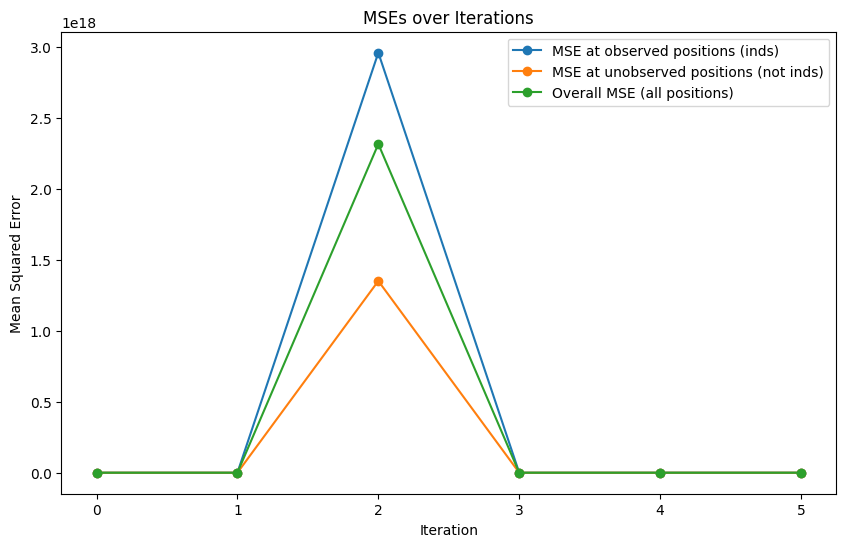

In [108]:
# adult_path = "/Users/ceciliaferrando/Documents/UMASS/RESEARCH/DPsynthesisML/hd-datasets-master/clean/adult.csv"
adult_path = "/Users/ceciliaferrando/Documents/UMASS/RESEARCH/DPsynthesisML/hd-datasets-master/clean/adult_d4.csv"

# Run the driver function
results_iter = run_driver(
    data_path = "synthdata.csv", # "synthdata.csv",
    structure='chain',
    structure_dict='None',
    max_iters=500,  # Number of iterations for optimization
    iterative=True,  
    max_off_diag_percentage=0.5,
    apply_dp=True,
    rho=2.0,
    alpha=0.5
)

In [70]:
results_adult_iter

{'mses': {'mse_inds': 1.0990772961148034e-23,
  'mse_not_inds': 0.0012260884276733266,
  'mse_all': 0.0005885224452831968},
 'g_vals': [0.6222637547227483,
  0.5385312132108698,
  0.2951204250743048,
  0.18350500095359726,
  0.10205581518763479,
  0.12967923313712346,
  0.10319183844158736,
  0.043608190368490944,
  0.026295145223537666,
  0.018657131960579,
  0.010213699846489926,
  0.006379380255571138,
  0.0074210572328838875,
  0.003561948848597285,
  0.0020335908689789184,
  0.0015720162328514975,
  0.0006098204123781842,
  0.00022158011144958467,
  0.00011810252266555854,
  2.9308844912007137e-05,
  1.3716171334915428e-05,
  2.1219356730411976e-05,
  2.3120332850457004e-06,
  1.3802079764091424e-06,
  6.640650721673191e-07,
  3.1313165443913604e-07,
  1.4742152967817113e-07,
  4.851131048255741e-08,
  2.8482597891343886e-08,
  1.9093615508114503e-08,
  1.1682032632909234e-08,
  7.802656146194131e-09,
  1.1599209009949263e-08,
  9.345635529345309e-09,
  7.151693709461782e-09,
  5.

data        age  workclass  fnlwgt  education
0        8          5       1          9
1       12          1       1          9
2        8          0       4         11
3       13          0       4          1
4        4          0       7          9
...    ...        ...     ...        ...
48837    8          0       4          9
48838   18          8       6         11
48839    8          0       7          9
48840   10          0       1          9
48841    7          2       3          9

[48842 rows x 4 columns]
s_v 0.4472135954999579, s_v 0.5477225575051661
Sigma_tilde_vec [0.14576224 0.30452138 0.02193235 0.2667659 ]
Sigma_tilde [[0.14576224 0.         0.         0.        ]
 [0.         0.30452138 0.         0.        ]
 [0.         0.         0.02193235 0.        ]
 [0.         0.         0.         0.2667659 ]]
Sigma_true [[ 0.1456715   0.02084411 -0.00440795 -0.0029097 ]
 [ 0.02084411  0.30463326 -0.00174751  0.00670595]
 [-0.00440795 -0.00174751  0.02179099 -0.00171262]
 [-

/var/folders/_v/3q83tdz16dz82yk206z719v40000gn/T/ipykernel_48431/3096491151.py:18: RuntimeWarning: invalid value encountered in log
  log_det_term = np.log(np.linalg.det(K_z))


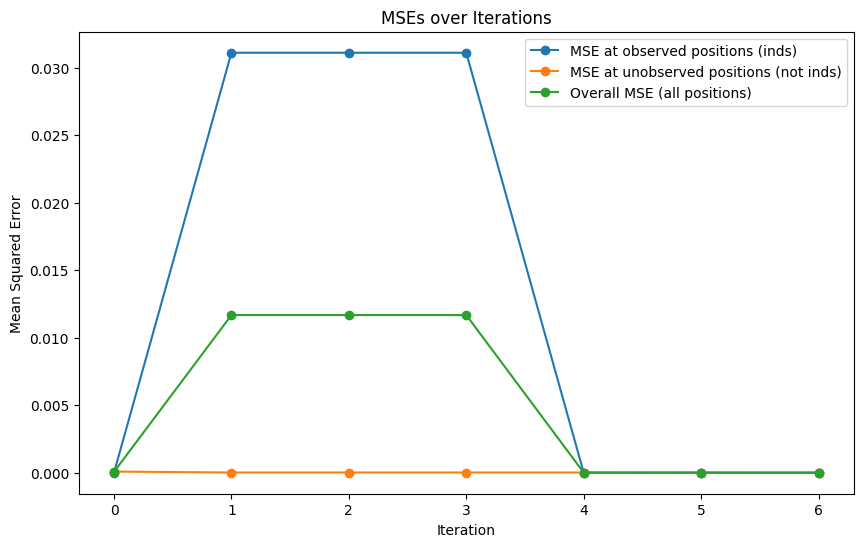

In [51]:
import numpy as np
from scipy.linalg import eigh, inv
from scipy.optimize import minimize


def loss_fn(z, inds, Sigma_tilde_vec, d):
    """
    z [np.array]: vector supporting precision matrix estimate K(z)
    inds [np.array]: list of the lower triangular nonzero element indices in Sigma_tilde
    Sigma_tilde_vec [np.array]: vector of Sigma_tilde indexed at inds
    d [int]: static argument, number of attributes 
    """

    # Reconstruct K_z
    K_z = get_K(z, inds, d)

    # Get loss terms
    log_det_term = np.log(np.linalg.det(K_z))
    trace_term = 2 * np.dot(z, Sigma_tilde_vec)

    # Total loss
    total_loss = -log_det_term + trace_term
    return total_loss


def get_K(z, inds, d):
    """
    z [np.array]: vector supporting precision matrix estimate K(z)
    inds [np.array]: list of the lower triangular nonzero element indices in Sigma_tilde
    d: dimension of Sigma_tilde
    """

    rows = inds[:, 0]
    cols = inds[:, 1]

    K = np.zeros((d, d))

    # Write lower triangle
    K[rows, cols] += z

    # Write upper triangle (diagonal elements are counted twice)
    K[cols, rows] += z

    return K


def initialize_z(Sigma_tilde, inds):
    """
    Sigma_tilde [np.array]: matrix of observed (privatized) covariance entries
    inds [np.array]: vector of indices of nonzero covariance entries
    """

    z_init = []
    for (i, j) in inds:
        if i == j:
            z_init.append(max(0.01, 1. / Sigma_tilde[i, j]) / 2)  # Diagonal halved
        else:
            z_init.append(0)

    return np.array(z_init)


def optimize_lbfgs(Sigma_tilde_vec, z, inds, d, max_iters=100, verbose=False):
    """
    Sigma_tilde_vec [np.array]: vector of observed (privatized) covariance entries
    z [np.array]: vector supporting K(z)
    inds [np.array]: vector of indices of nonzero covariance entries
    d [int]: number of attributes
    """

    # Loss function for optimization
    def loss_fn_wrapper(z):
        return loss_fn(z, inds, Sigma_tilde_vec, d)

    # Gradient function
    def grad_fn(z):
        epsilon = 1e-8  # Small value for numerical gradient approximation
        grad = np.zeros_like(z)
        for i in range(len(z)):
            z_eps = z.copy()
            z_eps[i] += epsilon
            grad[i] = (loss_fn_wrapper(z_eps) - loss_fn_wrapper(z)) / epsilon
        return grad

    # Callback to track optimization process
    obj_vals = []
    g_vals = []

    def callback(z):
        v = loss_fn_wrapper(z)
        g = np.sum(np.abs(grad_fn(z)))
        obj_vals.append(v)
        g_vals.append(g)
        if verbose:
            print(f"Objective Value: {v}, Gradient Sum: {g}")

    # Minimize using scipy L-BFGS
    result = minimize(
        fun=loss_fn_wrapper,
        x0=z,
        jac=grad_fn,  # Gradient function
        method='L-BFGS-B',  # L-BFGS optimization
        options={'maxiter': max_iters},
        callback=callback
    )

    # Optimization results
    z_opt = result.x
    return z_opt, g_vals, obj_vals


# Run the driver function
results_adult_iter = run_driver(
    data_path = adult_path, # "synthdata.csv",
    structure='custom',
    structure_dict=None,
    max_iters=1000,  # Number of iterations for optimization
    iterative=True,  
    max_off_diag_percentage=1.0,
    apply_dp=True,
    rho=10.0,
    alpha=0.5
)